# 3.1 Homogeneous Equations with Constant Coefficients

A second-order equation involves the second derivative of the unknown function. This section defines **linear** second-order equations and their initial value problems, then solves the simplest important case: homogeneous equations with **constant coefficients**,

$$ay'' + by' + cy = 0.$$

The method is to try $y = e^{rt}$, which turns the differential equation into a quadratic equation for $r$. This section treats the case where that quadratic has two **distinct real roots**. Complex roots and repeated roots are in Sections 3.3 and 3.4.

Reference: Boyce & DiPrima, *Elementary Differential Equations and Boundary Value Problems*, 11th ed., §3.1.

## Quick note: solving $ay'' + by' + cy = 0$ by hand

**Use:** constant coefficients, right-hand side zero, characteristic roots real and different ($b^2 - 4ac > 0$).

1. Replace $y''$, $y'$, $y$ by $r^2$, $r$, $1$: **characteristic equation** $ar^2 + br + c = 0$.
2. Find the roots $r_1 \ne r_2$ (factor, or $r = \dfrac{-b \pm \sqrt{b^2 - 4ac}}{2a}$).
3. General solution: $y = c_1 e^{r_1 t} + c_2 e^{r_2 t}$.
4. For an IVP, differentiate, $y' = c_1 r_1 e^{r_1 t} + c_2 r_2 e^{r_2 t}$, put in $t = t_0$ and solve the two linear equations for $c_1, c_2$.

**Example:** $y'' + 5y' + 6y = 0$, $y(0) = 2$, $y'(0) = 3$.

- Characteristic equation: $r^2 + 5r + 6 = (r + 2)(r + 3) = 0$, so $r_1 = -2$, $r_2 = -3$.
- General solution: $y = c_1 e^{-2t} + c_2 e^{-3t}$.
- At $t = 0$: $c_1 + c_2 = 2$ and $-2c_1 - 3c_2 = 3$.
- Add twice the first to the second: $-c_2 = 7$, so $c_2 = -7$ and $c_1 = 9$.
- **Answer:** $y = 9e^{-2t} - 7e^{-3t}$.

**Check:** $y(0) = 9 - 7 = 2$ and $y'(0) = -18 + 21 = 3$. ✓

**Tips**

- Always check the initial conditions at the end; it takes ten seconds and catches most sign errors.
- If $t_0 \ne 0$, either keep the factors $e^{r t_0}$ or write the solution as $c_1 e^{r_1 (t - t_0)} + c_2 e^{r_2 (t - t_0)}$; then the equations at $t_0$ are as simple as at $0$.
- A root $r = 0$ gives the solution $e^{0t} = 1$, a constant.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (7, 4.5)
plt.rcParams["axes.grid"] = True
np.set_printoptions(precision=6, suppress=True)

## 1. Second-order linear equations

A second-order ODE has the form

$$\frac{d^2 y}{dt^2} = f\!\left(t,\ y,\ \frac{dy}{dt}\right).$$

It is **linear** if $f$ is linear in $y$ and $y'$, that is $f = g(t) - p(t)\,y' - q(t)\,y$:

$$y'' + p(t)\,y' + q(t)\,y = g(t).$$

Equivalently, $P(t)\,y'' + Q(t)\,y' + R(t)\,y = G(t)$; dividing by $P(t)$ gives the first form wherever $P(t) \ne 0$. An equation that is not of this form is **nonlinear**.

| Equation | Linear? | Why |
|---|---|---|
| $y'' + 3y' + 2y = \sin t$ | yes | constant coefficients, $g(t) = \sin t$ |
| $t^2 y'' + t y' + (t^2 - 4)y = 0$ | yes | coefficients depend on $t$ only (Bessel's equation) |
| $y'' + \sin y = 0$ | no | $\sin y$ is not linear in $y$ (pendulum) |
| $y'' + y\,y' = 0$ | no | the product $y\,y'$ |

**Homogeneous or nonhomogeneous.** The equation is **homogeneous** if $g(t) = 0$ (or $G(t) = 0$) for all $t$, and **nonhomogeneous** otherwise. ("Homogeneous" here has nothing to do with the homogeneous first-order equations $y' = F(y/t)$.) Sections 3.1 to 3.4 deal with homogeneous equations; Section 3.5 shows that solving a nonhomogeneous equation reduces to the homogeneous one plus one particular solution.

**Initial value problem.** A first-order equation needed one condition. A second-order equation needs **two**, the position and the velocity at the starting time:

$$y'' + p(t)\,y' + q(t)\,y = g(t), \qquad y(t_0) = y_0, \qquad y'(t_0) = y_0'.$$

Geometrically, the solution must pass through $(t_0, y_0)$ **with slope** $y_0'$. Section 3.2 proves that when $p, q, g$ are continuous this IVP has exactly one solution.

## 2. Constant coefficients: a first example

From here on, the coefficients are constants:

$$ay'' + by' + cy = 0, \qquad a \ne 0.$$

**Example 1.** $y'' - y = 0$.

We need a function whose second derivative equals itself. Calculus gives two at once: $y_1 = e^{t}$ and $y_2 = e^{-t}$. More generally, any combination

$$y = c_1 e^{t} + c_2 e^{-t}$$

is also a solution, since $y'' = c_1 e^{t} + c_2 e^{-t} = y$. This is a **two-parameter family**, one constant for each of the two initial conditions.

**Choosing the constants.** For $y(0) = 2$, $y'(0) = -1$:

$$c_1 + c_2 = 2, \qquad c_1 - c_2 = -1 \quad\Longrightarrow\quad c_1 = \tfrac12,\ c_2 = \tfrac32,$$

so $y = \tfrac12 e^{t} + \tfrac32 e^{-t}$.

The plot shows several members of the family. All of them grow eventually unless $c_1 = 0$: the $e^{-t}$ part dies out and the $e^{t}$ part takes over.

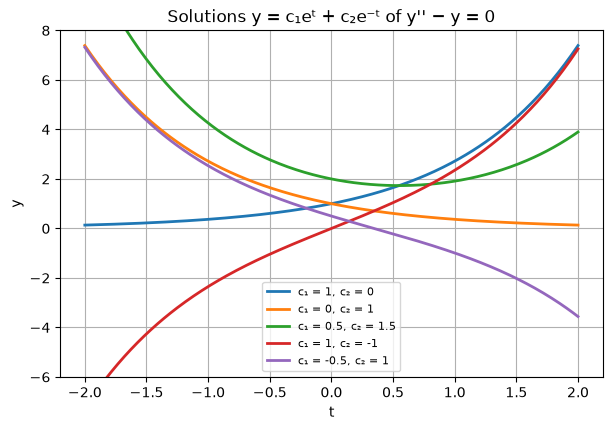

In [2]:
t = np.linspace(-2, 2, 300)
for c1, c2 in [(1, 0), (0, 1), (0.5, 1.5), (1, -1), (-0.5, 1)]:
    plt.plot(t, c1 * np.exp(t) + c2 * np.exp(-t), lw=2, label=f"c₁ = {c1}, c₂ = {c2}")
plt.ylim(-6, 8)
plt.xlabel("t"); plt.ylabel("y")
plt.title("Solutions y = c₁eᵗ + c₂e⁻ᵗ of y'' − y = 0")
plt.legend(fontsize=8);

## 3. The characteristic equation

Example 1 suggests looking for solutions of the form $y = e^{rt}$, with $r$ to be found. Then $y' = re^{rt}$ and $y'' = r^2 e^{rt}$, and substituting into $ay'' + by' + cy = 0$ gives

$$(ar^2 + br + c)\,e^{rt} = 0.$$

Since $e^{rt}$ is never zero, $y = e^{rt}$ is a solution exactly when

$$\boxed{ar^2 + br + c = 0}$$

This is the **characteristic equation** of the differential equation. A differential equation has become an algebra problem.

**Shortcut:** read it straight off the ODE by replacing $y'' \to r^2$, $y' \to r$, $y \to 1$.

The roots $r = \dfrac{-b \pm \sqrt{b^2 - 4ac}}{2a}$ fall into three cases:

| Discriminant | Roots | Solutions | Section |
|---|---|---|---|
| $b^2 - 4ac > 0$ | real and distinct, $r_1 \ne r_2$ | $e^{r_1 t}$, $e^{r_2 t}$ | **3.1** |
| $b^2 - 4ac < 0$ | complex conjugates $\lambda \pm i\mu$ | $e^{\lambda t}\cos \mu t$, $e^{\lambda t}\sin \mu t$ | 3.3 |
| $b^2 - 4ac = 0$ | repeated, $r_1 = r_2$ | $e^{r_1 t}$, $te^{r_1 t}$ | 3.4 |

## 4. Distinct real roots

If $r_1 \ne r_2$ are real, then $y_1 = e^{r_1 t}$ and $y_2 = e^{r_2 t}$ are solutions, and so is every combination

$$\boxed{y = c_1 e^{r_1 t} + c_2 e^{r_2 t}}$$

**Why combinations are solutions.** Write $L[y] = ay'' + by' + cy$. Differentiation is linear, so

$$L[c_1 y_1 + c_2 y_2] = c_1 L[y_1] + c_2 L[y_2] = c_1 \cdot 0 + c_2 \cdot 0 = 0.$$

This is the **superposition principle**; it works for every linear homogeneous equation, not only constant-coefficient ones (Section 3.2).

**Any initial conditions can be met.** Impose $y(t_0) = y_0$, $y'(t_0) = y_0'$:

$$
\begin{aligned}
c_1 e^{r_1 t_0} + c_2 e^{r_2 t_0} &= y_0,\\
c_1 r_1 e^{r_1 t_0} + c_2 r_2 e^{r_2 t_0} &= y_0'.
\end{aligned}
$$

The determinant of this linear system is $(r_2 - r_1)\,e^{(r_1 + r_2)t_0}$, which is nonzero because $r_1 \ne r_2$. So there is always exactly one solution, and Cramer's rule gives

$$c_1 = \frac{y_0' - y_0 r_2}{r_1 - r_2}\,e^{-r_1 t_0}, \qquad c_2 = \frac{y_0 r_1 - y_0'}{r_1 - r_2}\,e^{-r_2 t_0}.$$

Because every IVP can be solved by a member of the family, the family contains *every* solution: it is the **general solution**. (Section 3.2 makes this argument precise with the Wronskian; the determinant above is exactly the Wronskian of $e^{r_1 t}$ and $e^{r_2 t}$ at $t_0$.)

The code below turns these formulas into a small solver.

In [3]:
def char_roots(a, b, c):
    # Real, distinct roots of a r^2 + b r + c = 0, larger root first.
    disc = b**2 - 4 * a * c
    if disc <= 0:
        raise ValueError(f"b² − 4ac = {disc}: roots are not real and distinct (see Sections 3.3, 3.4)")
    r = sorted([(-b + np.sqrt(disc)) / (2 * a), (-b - np.sqrt(disc)) / (2 * a)], reverse=True)
    return float(r[0]), float(r[1])

def solve_ivp_const(a, b, c, t0, y0, yp0):
    # Constants of y = c1 e^{r1 t} + c2 e^{r2 t} that satisfy y(t0) = y0, y'(t0) = yp0.
    r1, r2 = char_roots(a, b, c)
    c1 = (yp0 - y0 * r2) / (r1 - r2) * np.exp(-r1 * t0)
    c2 = (y0 * r1 - yp0) / (r1 - r2) * np.exp(-r2 * t0)
    y = lambda t: c1 * np.exp(r1 * t) + c2 * np.exp(r2 * t)
    dy = lambda t: c1 * r1 * np.exp(r1 * t) + c2 * r2 * np.exp(r2 * t)
    return (r1, r2), (c1, c2), y, dy

def residual(a, b, c, y, dy, t, h=1e-4):
    # a y'' + b y' + c y, with y'' from a central difference of y'; should be ≈ 0.
    d2y = (dy(t + h) - dy(t - h)) / (2 * h)
    return a * d2y + b * dy(t) + c * y(t)

# Example 1: y'' − y = 0, y(0) = 2, y'(0) = −1
roots, consts, y, dy = solve_ivp_const(1, 0, -1, 0, 2, -1)
print(f"roots r1 = {roots[0]:g}, r2 = {roots[1]:g};  constants c1 = {consts[0]:g}, c2 = {consts[1]:g}")
print(f"max |residual| on [0, 2]: {np.max(np.abs(residual(1, 0, -1, y, dy, np.linspace(0, 2, 50)))):.1e}")

roots r1 = 1, r2 = -1;  constants c1 = 0.5, c2 = 1.5
max |residual| on [0, 2]: 6.5e-09


## 5. Worked examples

**Example 2.** Find the general solution of $y'' + 5y' + 6y = 0$.

$r^2 + 5r + 6 = (r + 2)(r + 3) = 0$ gives $r_1 = -2$, $r_2 = -3$, so

$$y = c_1 e^{-2t} + c_2 e^{-3t}.$$

**Example 3.** Solve $y'' + 5y' + 6y = 0$, $y(0) = 2$, $y'(0) = 3$.

From Example 2, $y' = -2c_1 e^{-2t} - 3c_2 e^{-3t}$. At $t = 0$:

$$c_1 + c_2 = 2, \qquad -2c_1 - 3c_2 = 3 \quad\Longrightarrow\quad c_1 = 9,\ c_2 = -7,$$

$$y = 9e^{-2t} - 7e^{-3t}.$$

**Example 4.** The solution of Example 3 starts at $y = 2$ with positive slope, so it rises first and then decays to zero. Find its maximum.

Set $y' = -18e^{-2t} + 21e^{-3t} = 0$. Multiplying by $e^{3t}$ gives $18e^{t} = 21$, so

$$t_m = \ln\tfrac{7}{6} \approx 0.1542, \qquad y_m = 9\left(\tfrac{6}{7}\right)^2 - 7\left(\tfrac{6}{7}\right)^3 = \tfrac{108}{49} \approx 2.2041.$$

Example 3: r = -2, -3;  c1 = 9, c2 = -7
Example 4: t_m = 0.1542, y(t_m) = 2.2041, 108/49 = 2.2041, y'(t_m) = 0.0e+00


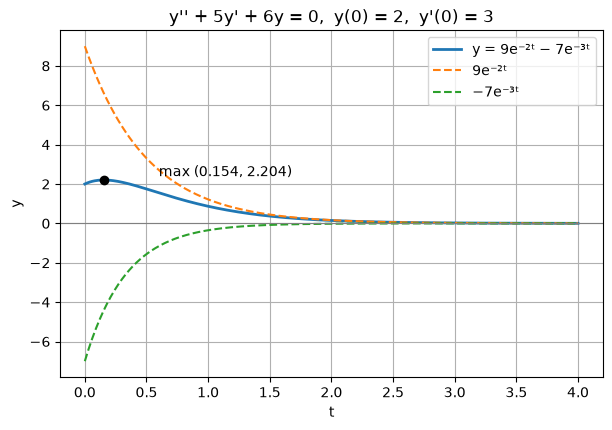

In [4]:
(r1, r2), (c1, c2), y, dy = solve_ivp_const(1, 5, 6, 0, 2, 3)
print(f"Example 3: r = {r1:g}, {r2:g};  c1 = {c1:g}, c2 = {c2:g}")

tm = np.log(7 / 6)
print(f"Example 4: t_m = {tm:.4f}, y(t_m) = {y(tm):.4f}, 108/49 = {108/49:.4f}, y'(t_m) = {dy(tm):.1e}")

t = np.linspace(0, 4, 400)
plt.plot(t, y(t), lw=2, label="y = 9e⁻²ᵗ − 7e⁻³ᵗ")
plt.plot(t, 9 * np.exp(-2 * t), "--", label="9e⁻²ᵗ")
plt.plot(t, -7 * np.exp(-3 * t), "--", label="−7e⁻³ᵗ")
plt.plot(tm, y(tm), "ko")
plt.annotate(f"max ({tm:.3f}, {y(tm):.3f})", (tm, y(tm)), xytext=(0.6, 2.4))
plt.axhline(0, color="gray", lw=0.8)
plt.xlabel("t"); plt.ylabel("y")
plt.title("y'' + 5y' + 6y = 0,  y(0) = 2,  y'(0) = 3")
plt.legend();

Both exponentials decay, so $y \to 0$. The slower one, $e^{-2t}$, decides how fast: for large $t$, $y \approx 9e^{-2t}$.

**Example 5.** Solve $4y'' - 8y' + 3y = 0$, $y(0) = 2$, $y'(0) = \tfrac12$.

$4r^2 - 8r + 3 = (2r - 1)(2r - 3) = 0$ gives $r = \tfrac12, \tfrac32$, so $y = c_1 e^{t/2} + c_2 e^{3t/2}$ and

$$c_1 + c_2 = 2, \qquad \tfrac12 c_1 + \tfrac32 c_2 = \tfrac12 \quad\Longrightarrow\quad c_1 = \tfrac52,\ c_2 = -\tfrac12,$$

$$y = \tfrac52 e^{t/2} - \tfrac12 e^{3t/2}.$$

Both roots are positive, but the coefficient of the faster exponential $e^{3t/2}$ is negative. That term eventually wins, so $y \to -\infty$. The solution crosses zero where $5e^{t/2} = e^{3t/2}$, i.e. $e^{t} = 5$, $t = \ln 5 \approx 1.609$.

Example 5: r = 1.5, 0.5;  coefficient of e^(3t/2) = -0.5, of e^(t/2) = 2.5
y(ln 5) = 1.8e-15


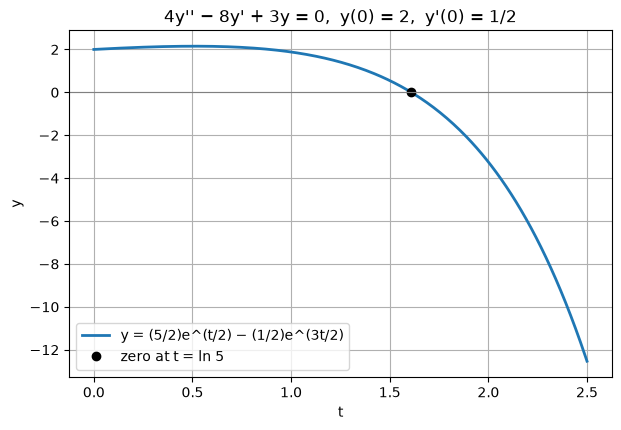

In [5]:
(r1, r2), (c1, c2), y, dy = solve_ivp_const(4, -8, 3, 0, 2, 0.5)
print(f"Example 5: r = {r1:g}, {r2:g};  coefficient of e^(3t/2) = {c1:g}, of e^(t/2) = {c2:g}")
print(f"y(ln 5) = {y(np.log(5)):.1e}")

t = np.linspace(0, 2.5, 300)
plt.plot(t, y(t), lw=2, label="y = (5/2)e^(t/2) − (1/2)e^(3t/2)")
plt.plot(np.log(5), 0, "ko", label="zero at t = ln 5")
plt.axhline(0, color="gray", lw=0.8)
plt.xlabel("t"); plt.ylabel("y")
plt.title("4y'' − 8y' + 3y = 0,  y(0) = 2,  y'(0) = 1/2")
plt.legend();

**Example 6 (initial time not zero).** Solve $y'' - y' - 2y = 0$, $y(1) = 1$, $y'(1) = 0$.

$r^2 - r - 2 = (r - 2)(r + 1)$, so $r = 2, -1$. Writing the solution in terms of $t - 1$,

$$y = A e^{2(t - 1)} + B e^{-(t - 1)}, \qquad A + B = 1, \quad 2A - B = 0 \quad\Longrightarrow\quad A = \tfrac13,\ B = \tfrac23.$$

So $y = \tfrac13 e^{2(t-1)} + \tfrac23 e^{-(t-1)}$, which equals $\tfrac{1}{3e^2} e^{2t} + \tfrac{2e}{3} e^{-t}$: the same answer as $c_1 = \tfrac13 e^{-2}$, $c_2 = \tfrac23 e$ from the formulas in Section 4.

In [6]:
_, (c1, c2), y, dy = solve_ivp_const(1, -1, -2, 1, 1, 0)
print(f"c1 = {c1:.6f}  (e⁻²/3 = {np.exp(-2)/3:.6f})")
print(f"c2 = {c2:.6f}  (2e/3  = {2*np.e/3:.6f})")
print(f"y(1) = {y(1):.6f}, y'(1) = {dy(1):.1e}")

c1 = 0.045112  (e⁻²/3 = 0.045112)
c2 = 1.812188  (2e/3  = 1.812188)
y(1) = 1.000000, y'(1) = 0.0e+00


**Example 7 (choosing an initial value).** For $y'' - y' - 2y = 0$, $y(0) = \alpha$, $y'(0) = 2$, find $\alpha$ so that the solution tends to $0$ as $t \to \infty$.

With $r = 2, -1$: $c_1 + c_2 = \alpha$ and $2c_1 - c_2 = 2$, so $c_1 = \tfrac{\alpha + 2}{3}$, $c_2 = \tfrac{2\alpha - 2}{3}$.

The term $e^{2t}$ grows, so $y \to 0$ only if its coefficient vanishes: $\alpha = -2$, which gives $y = -2e^{-t}$. For any other $\alpha$ the solution blows up, towards $+\infty$ if $\alpha > -2$ and $-\infty$ if $\alpha < -2$.

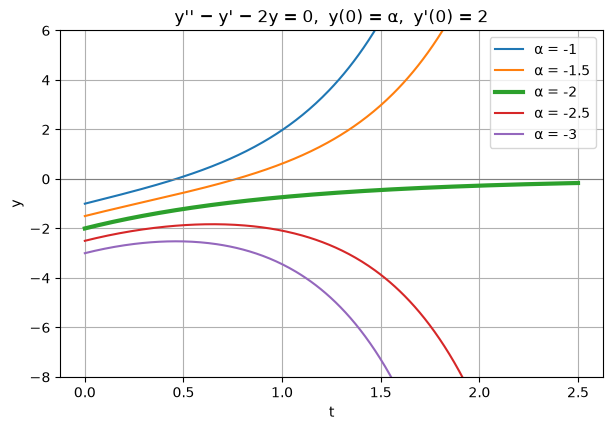

In [7]:
t = np.linspace(0, 2.5, 300)
for alpha in [-1, -1.5, -2, -2.5, -3]:
    *_, y, _ = solve_ivp_const(1, -1, -2, 0, alpha, 2)
    plt.plot(t, y(t), lw=3 if alpha == -2 else 1.5, label=f"α = {alpha}")
plt.ylim(-8, 6)
plt.axhline(0, color="gray", lw=0.8)
plt.xlabel("t"); plt.ylabel("y")
plt.title("y'' − y' − 2y = 0,  y(0) = α,  y'(0) = 2")
plt.legend();

Only the bold curve $\alpha = -2$ stays bounded. A tiny change in $\alpha$ switches on the growing term, so this solution is very sensitive to its initial value.

## 6. Long-term behaviour

For $y = c_1 e^{r_1 t} + c_2 e^{r_2 t}$ with $r_1 > r_2$, the term with the larger root dominates for large $t$ (when $c_1 \ne 0$). So the behaviour as $t \to \infty$ is decided by the signs of the roots:

| Roots | Typical solution as $t \to \infty$ |
|---|---|
| both negative | $y \to 0$ for every initial condition |
| $r_1 = 0$, $r_2 < 0$ | $y \to c_1$, a constant |
| $r_1 > 0 > r_2$ | $\lvert y\rvert \to \infty$, except when $c_1 = 0$ (then $y \to 0$) |
| both positive | $\lvert y \rvert \to \infty$, except $y \equiv 0$ |

The signs can be read from the coefficients without solving: $r_1 r_2 = c/a$ and $r_1 + r_2 = -b/a$. For example, if $a, b, c$ are all positive, both roots are negative and every solution decays. This is the situation for a damped spring (Section 3.7).

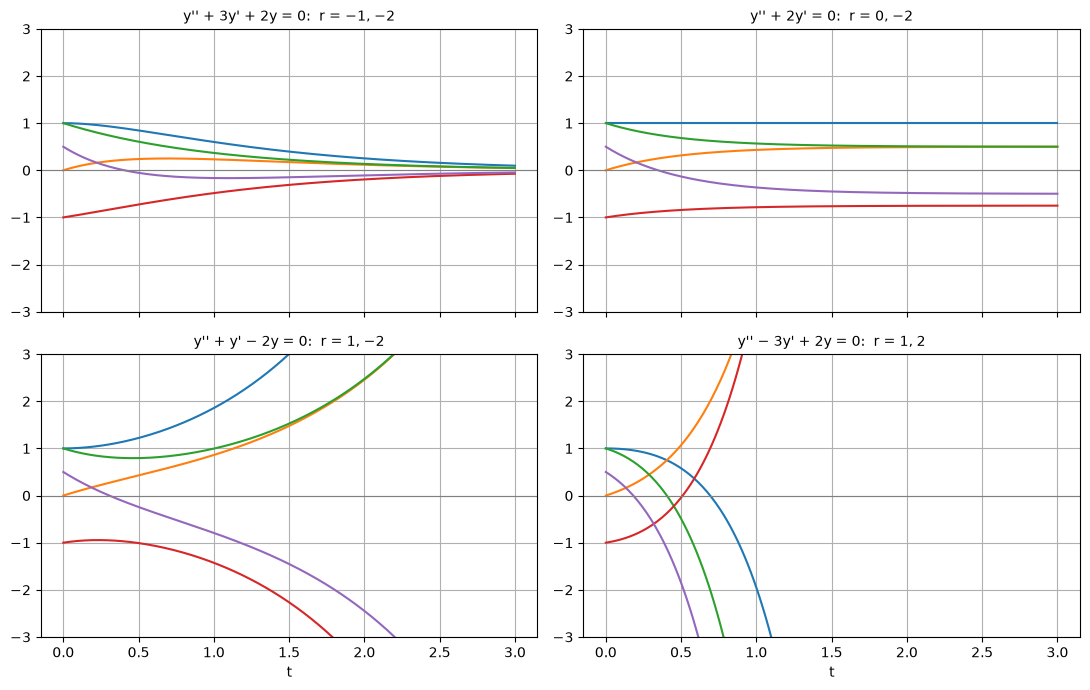

In [8]:
cases = [((1, 3, 2), "y'' + 3y' + 2y = 0:  r = −1, −2"),
         ((1, 2, 0), "y'' + 2y' = 0:  r = 0, −2"),
         ((1, 1, -2), "y'' + y' − 2y = 0:  r = 1, −2"),
         ((1, -3, 2), "y'' − 3y' + 2y = 0:  r = 1, 2")]
t = np.linspace(0, 3, 300)
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
for ax, ((a, b, c), title) in zip(axes.flat, cases):
    for y0, yp0 in [(1, 0), (0, 1), (1, -1), (-1, 0.5), (0.5, -2)]:
        *_, y, _ = solve_ivp_const(a, b, c, 0, y0, yp0)
        ax.plot(t, y(t), lw=1.5)
    ax.set_title(title, fontsize=10)
    ax.set_ylim(-3, 3)
    ax.axhline(0, color="gray", lw=0.8)
for ax in axes[1]:
    ax.set_xlabel("t")
plt.tight_layout()

## 7. A numerical check

As shown in [Numerical Methods, Section 8](../numerical-methods/08-systems-and-higher-order.ipynb), a second-order equation becomes a first-order **system** by introducing the velocity $v = y'$:

$$y' = v, \qquad v' = -\frac{b\,v + c\,y}{a}.$$

Solving Example 3 this way with RK4 and comparing with $9e^{-2t} - 7e^{-3t}$ is an independent check of the formula. When $h$ is halved the error ratio approaches $2^4 = 16$, as expected for a fourth-order method.

In [9]:
def rk4_system(F, t0, u0, h, n):
    t, u = t0 + h * np.arange(n + 1), np.zeros((n + 1, len(u0)))
    u[0] = u0
    for i in range(n):
        k1 = F(t[i], u[i])
        k2 = F(t[i] + h / 2, u[i] + h / 2 * k1)
        k3 = F(t[i] + h / 2, u[i] + h / 2 * k2)
        k4 = F(t[i] + h, u[i] + h * k3)
        u[i + 1] = u[i] + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
    return t, u

a, b, c = 1, 5, 6
F = lambda t, u: np.array([u[1], -(b * u[1] + c * u[0]) / a])
exact = lambda t: 9 * np.exp(-2 * t) - 7 * np.exp(-3 * t)

prev = None
for h in [0.2, 0.1, 0.05, 0.025]:
    t, u = rk4_system(F, 0, [2, 3], h, round(4 / h))
    err = np.max(np.abs(u[:, 0] - exact(t)))
    print(f"h = {h:5}: max error on [0, 4] = {err:.3e}" + (f",  ratio {prev / err:.1f}" if prev else ""))
    prev = err

h =   0.2: max error on [0, 4] = 3.558e-03
h =   0.1: max error on [0, 4] = 1.755e-04,  ratio 20.3
h =  0.05: max error on [0, 4] = 9.563e-06,  ratio 18.4
h = 0.025: max error on [0, 4] = 5.580e-07,  ratio 17.1


## 8. Summary

| Step | What to do |
|---|---|
| 1 | Write the characteristic equation $ar^2 + br + c = 0$ |
| 2 | Find the roots; this section needs $b^2 - 4ac > 0$, giving $r_1 \ne r_2$ |
| 3 | General solution $y = c_1 e^{r_1 t} + c_2 e^{r_2 t}$ |
| 4 | Use $y(t_0)$ and $y'(t_0)$ to find $c_1$, $c_2$ |
| 5 | Check the initial conditions; read off the behaviour from the dominant exponential |

* A second-order IVP needs two conditions: $y(t_0)$ and $y'(t_0)$.
* Linear homogeneous equations obey the **superposition principle**: combinations of solutions are solutions.
* For large $t$ the term with the **larger root** dominates, unless its coefficient is zero.

## Exercises

Find the general solution.

1. $y'' + 2y' - 3y = 0$
2. $6y'' - y' - y = 0$
3. $y'' + 4y' = 0$
4. $y'' - 9y = 0$

Solve the initial value problem, and describe the behaviour as $t \to \infty$.

5. $y'' + y' - 2y = 0$, $y(0) = 1$, $y'(0) = 1$
6. $y'' + 3y' = 0$, $y(0) = -2$, $y'(0) = 3$
7. $2y'' - 3y' + y = 0$, $y(0) = 2$, $y'(0) = \tfrac12$. Also find the maximum value of the solution and where it crosses zero.

Further problems.

8. Find a differential equation whose general solution is $y = c_1 e^{2t} + c_2 e^{-3t}$.
9. For $y'' - y' - 6y = 0$, $y(0) = 1$, $y'(0) = \alpha$, find $\alpha$ so that $y \to 0$ as $t \to \infty$.
10. Show that if $a > 0$ and $c < 0$, the roots of $ar^2 + br + c = 0$ are always real with opposite signs, and conclude that almost every solution of $ay'' + by' + cy = 0$ is unbounded.

**Answers**

1. $r^2 + 2r - 3 = (r + 3)(r - 1)$: $y = c_1 e^{t} + c_2 e^{-3t}$.
2. $6r^2 - r - 1 = (2r - 1)(3r + 1)$: $y = c_1 e^{t/2} + c_2 e^{-t/3}$.
3. $r(r + 4) = 0$: $y = c_1 + c_2 e^{-4t}$.
4. $r = \pm 3$: $y = c_1 e^{3t} + c_2 e^{-3t}$.
5. $r = 1, -2$: $c_1 + c_2 = 1$, $c_1 - 2c_2 = 1$, so $y = e^{t}$, which grows without bound.
6. $r = 0, -3$: $c_1 + c_2 = -2$, $-3c_2 = 3$, so $y = -1 - e^{-3t}$, which tends to $-1$.
7. $r = 1, \tfrac12$: $y = -e^{t} + 3e^{t/2}$, which tends to $-\infty$. $y' = 0$ where $e^{t/2} = \tfrac32$, i.e. $t = 2\ln\tfrac32 \approx 0.811$, with maximum $y = \tfrac94$. Zero where $e^{t/2} = 3$, i.e. $t = \ln 9 \approx 2.197$.
8. $(r - 2)(r + 3) = r^2 + r - 6$: $y'' + y' - 6y = 0$.
9. $r = 3, -2$: $c_1 = \tfrac{\alpha + 2}{5}$, so $\alpha = -2$ (then $y = e^{-2t}$).
10. $b^2 - 4ac > 0$ because $-4ac > 0$, so the roots are real and distinct, and $r_1 r_2 = c/a < 0$, so one is positive. The positive root's term grows unless its coefficient is zero, which happens only for one particular ratio $y'(t_0)/y(t_0)$.

The cell below checks answers 5 to 9 numerically.

In [10]:
for k, (abc, y0, yp0, claim) in {
    5: ((1, 1, -2), 1, 1, lambda t: np.exp(t)),
    6: ((1, 3, 0), -2, 3, lambda t: -1 - np.exp(-3 * t)),
    7: ((2, -3, 1), 2, 0.5, lambda t: -np.exp(t) + 3 * np.exp(t / 2)),
}.items():
    *_, y, _ = solve_ivp_const(*abc, 0, y0, yp0)
    t = np.linspace(0, 3, 50)
    print(f"{k}. max |solver − answer| = {np.max(np.abs(y(t) - claim(t))):.1e}")

*_, y, _ = solve_ivp_const(2, -3, 1, 0, 2, 0.5)
print(f"7. y(2 ln 1.5) = {y(2 * np.log(1.5)):.6f},  y(ln 9) = {y(np.log(9)):.1e}")
print("8. roots of r² + r − 6:", char_roots(1, 1, -6))
_, (c1, c2), _, _ = solve_ivp_const(1, -1, -6, 0, 1, -2)
print(f"9. α = −2 gives c1 = {c1:.1e}, c2 = {c2:g}")

5. max |solver − answer| = 0.0e+00
6. max |solver − answer| = 0.0e+00
7. max |solver − answer| = 0.0e+00
7. y(2 ln 1.5) = 2.250000,  y(ln 9) = 0.0e+00
8. roots of r² + r − 6: (2.0, -3.0)
9. α = −2 gives c1 = 0.0e+00, c2 = 1
